# Hypothesis

1. The 2.00 GHz RFI will impact the observation to the same extend;


# Goal: 
- Investigate the 2.00 GHz peak on the observations:
- Load the data files;
- Understand each data files composition;
- Preper the data;\
-- Remove channel zero and the edge;\
-- Choose the data where the speed of the telescope is constant (by plotingn the Az and elev);\
-- If no turning, then `do` step 1 to 4, `else` select data for constant speed, then `do` step 1 to 4;\
-- Detrend the signal;
- 1. Select data around 2.00 GHz;
- 2. Plot the time average spectrum;
- 3. Plot the spectrum
- 4. Extrar the number of channels, prominence of the peak; 
-> Extrar scientific inference from the parameter information.

# Findings: 

rw-------@ 1 hkloeckner  wheel   1.6G  3 Jul 10:13 `EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5`\
 obsid 22228, S-Band, dual polarisation, cross scan, Taurus A


-rw-------@ 1 hkloeckner  wheel   2.4G  3 Jul 10:13 `EDD_2023-07-22T16_58_22.326155UTC_auMzw.hdf5`\
 obsid 29869, S-Band, dual polarisation, survey_scan (drift scan)


-rw-r--r--@ 1 hkloeckner  wheel   2.4G  3 Jul 10:13 `EDD_2023-08-09T19_46_45.289915UTC_viGdg.hdf5`\
 obsid 31399, S-Band, dual polarisation, nod scan


-rw-------@ 1 hkloeckner  wheel   4.1G  3 Jul 10:13 `EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5`\
 obsid 31168, S-Band, cross scan, dual polarisation, J1939-6342



-rw-r--r--@ 1 hkloeckner  wheel   4.1G  3 Jul 10:13 `EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5`\
 obsid XXXX, S-Band, dual polarisation, cross-scan, 3C138\
 (scan "000" Azimuth-Scan, "001" Elevation-Scan)\
 Nod-Scan through the source (scan "002")


-rw-r--r--@ 1 hkloeckner  wheel   8.9G  3 Jul 10:13 `EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5`\
 obsid XXXX, S-Band, dual polarisation, cross scan, SPASS_J054138-015457\
 (scan "000" Azimuth-Scan, "001" ist Elevation-Scan)\
 Nod-Scans through and aside the source (scan "002", "003" & "004")


In [1]:
import h5py
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import scienceplots
plt.style.use(['science', 'no-latex'])

from pybaselines import Baseline, utils
from datetime import datetime, timezone

from scipy.signal import find_peaks

from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models

from MPG_HDF5_libs import *

# Acesses all data files

In [2]:
import glob
import os

# --- Define directory containing HDF5 files ---
data_path = '/home/chavango/Master/DATA/SKAMPI_data/*.hdf5'

# --- Collect all files matching pattern ---
hdf5_files = sorted(glob.glob(data_path))

print(f"Found {len(hdf5_files)} HDF5 files:")
for fpath in hdf5_files:
    print("  •", os.path.basename(fpath))
print("-" * 60)

# --- Function to print the internal structure of each HDF5 file ---
def print_hdf5_structure(name, obj):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        print(f"{indent} Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent} Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")

# --- Loop through each file and display structure ---
for fpath in hdf5_files:
    print(f"\n=== Exploring file: {os.path.basename(fpath)} ===")
    with h5py.File(fpath, "r") as f:
        f.visititems(print_hdf5_structure)


Found 6 HDF5 files:
  • EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5
  • EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5
  • EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5
  • EDD_2023-07-22T16_58_22.326155UTC_auMzw.hdf5
  • EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5
  • EDD_2023-08-09T19_46_45.289915UTC_viGdg.hdf5
------------------------------------------------------------

=== Exploring file: EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5 ===
 Dataset: history, Shape: (9,), Dtype: [('processingtime', 'S23'), ('software', 'S256'), ('version', 'S128'), ('comment', 'S256')]
 Group: monitor
   Group: monitor/acu
     Dataset: monitor/acu/actual_timestamp, Shape: (2650,), Dtype: float64
     Group: monitor/acu/ambient_temp_correction_config
       Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_1, Shape: (2650,), Dtype: float64
       Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_10, Shape: (2650,), Dtype: float64
       Dataset: monitor

In [3]:
hdf5_files[0]

'/home/chavango/Master/DATA/SKAMPI_data/EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5'


=== File: EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5 ===
  • Group scan/000/P1_ND0: 
Azimute shape: (664,) 
Elevation shape: (664,) 
Spectrum shape: (634, 63877) 
Frequency shape: (63877,) 
time shape: (634, 1)


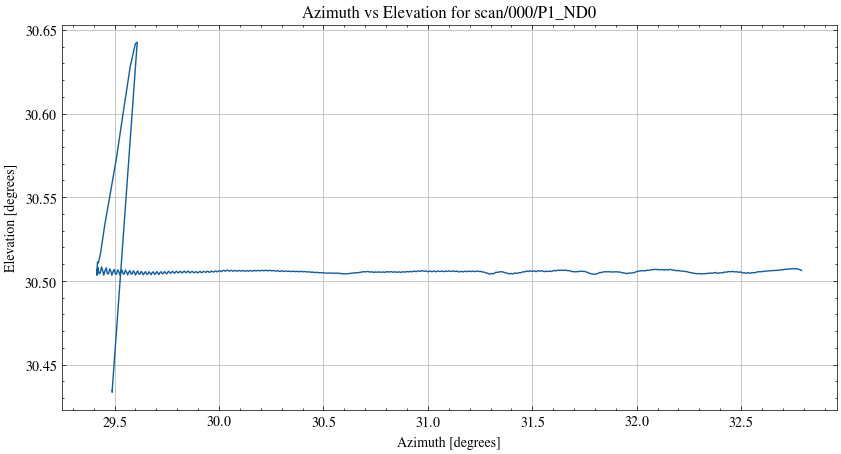

In [4]:
# plot the azi and elev

groups = [
     "scan/000/P1_ND0",
    #  "scan/000/P1_ND1",
    # "scan/001/P0_ND0",
    #  "scan/001/P0_ND1",
    #   "scan/001/P1_ND0",
    #   "scan/001/P1_ND1"
]


#for fpath in hdf5_files[0]:
fpath = hdf5_files[0]
print(f"\n=== File: {os.path.basename(fpath)} ===")

with h5py.File(fpath, "r") as f:
    try:
        for g in groups:
        
            # --- Access datasets ---
            freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
            spectrum = f[f"{g}/spectrum"][30:,1600:-60]        # (time × freq)
            time = f[f"{g}/timestamp"][30:]           # time samples
            azi = f[f"{g}/azimuth"][:]              # azimuth angles
            elev = f[f"{g}/elevation"][:]           # elevation angles

            print(f"  • Group {g}: \nAzimute shape: {azi.shape} \nElevation shape: {elev.shape} \n"
                  f"Spectrum shape: {spectrum.shape} \nFrequency shape: {freq.shape} \n"
                  f"time shape: {time.shape}")

                # --- Plot azimuth and elevation ---
            plt.figure(figsize=(10,5))
            plt.plot(azi, elev)
            
            plt.title(f'Azimuth vs Elevation for {g}')
            plt.xlabel('Azimuth [degrees]')
            plt.ylabel('Elevation [degrees]')
            plt.grid()
            plt.show()

    except KeyError as e:
            print(f"  ! Group {g} not found in file.")


In [5]:
# group1 = [
#     "scan/000/P1_ND0",
#      "scan/000/P1_ND1",
# ]

# group2 = [
#     "scan/001/P0_ND0",
#     "scan/001/P0_ND1",
# ]


# #for fpath in hdf5_files[0]:
# fpath = hdf5_files[0]
# print(f"\n=== File: {os.path.basename(fpath)} ===")

# with h5py.File(fpath, "r") as f:
#     try:
#         for g in group1:
        
#             # --- Access datasets ---
#             freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
#             spectrum = f[f"{g}/spectrum"][:,1600:-60]        # (time × freq)
#             time = f[f"{g}/timestamp"][:]           # time samples
#             azi = f[f"{g}/azimuth"][:]              # azimuth angles
#             elev = f[f"{g}/elevation"][:]           # elevation angles

#             print(f"  • Group {g}: \nAzimute shape: {azi.shape} \nElevation shape: {elev.shape} \n"
#                   f"Spectrum shape: {spectrum.shape} \nFrequency shape: {freq.shape} \n"
#                   f"time shape: {time.shape}")

#                 # --- Plot azimuth and elevation ---
#             plt.figure(figsize=(10,5))
#             plt.scatter(azi, elev)
            
#             plt.title(f'Azimuth vs Elevation for {g}')
#             plt.xlabel('Azimuth [degrees]')
#             plt.ylabel('Elevation [degrees]')
#             plt.grid()
#             plt.show()
        
#             break
            

#         # for g in group2:
#         #                  # --- Access datasets ---
#         #     freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
#         #     spectrum = f[f"{g}/spectrum"][:,1600:-60]        # (time × freq)
#         #     time = f[f"{g}/timestamp"][:]           # time samples
#         #     azi = f[f"{g}/azimuth"][:]              # azimuth angles
#         #     elev = f[f"{g}/elevation"][:]           # elevation angles

#         #     print(f"  • Group {g}: \nAzimute shape: {azi.shape} \nElevation shape: {elev.shape} \n"
#         #           f"Spectrum shape: {spectrum.shape} \nFrequency shape: {freq.shape} \n"
#         #           f"time shape: {time.shape}")

#         #         # --- Plot azimuth and elevation ---
#         #     plt.figure(figsize=(10,5))
#         #     plt.plot(azi, elev)
            
#         #     plt.title(f'Azimuth vs Elevation for {g}')
#         #     plt.xlabel('Azimuth [degrees]')
#         #     plt.ylabel('Elevation [degrees]')
#         #     plt.grid()
#         #     plt.show()
             

#     except KeyError as e:
#             print(f"  ! Group {g} not found in file.")


            


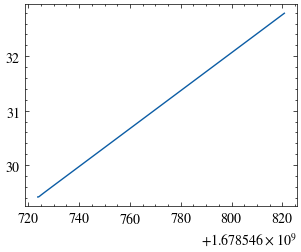

In [6]:
with h5py.File(fpath, "r") as f:
    try:
        for g in groups:
            freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
            spectrum = f[f"{g}/spectrum"][30:,1600:-60]        # (time × freq)
            time = f[f"{g}/timestamp"][30:,0]           # time samples
            azi = f[f"{g}/azimuth"][30:]              # azimuth angles
            elev = f[f"{g}/elevation"][30:]           # elevation angles


            plt.plot(time, azi)

    except KeyError as e:
            print(f"  ! Group {g} not found in file.") 

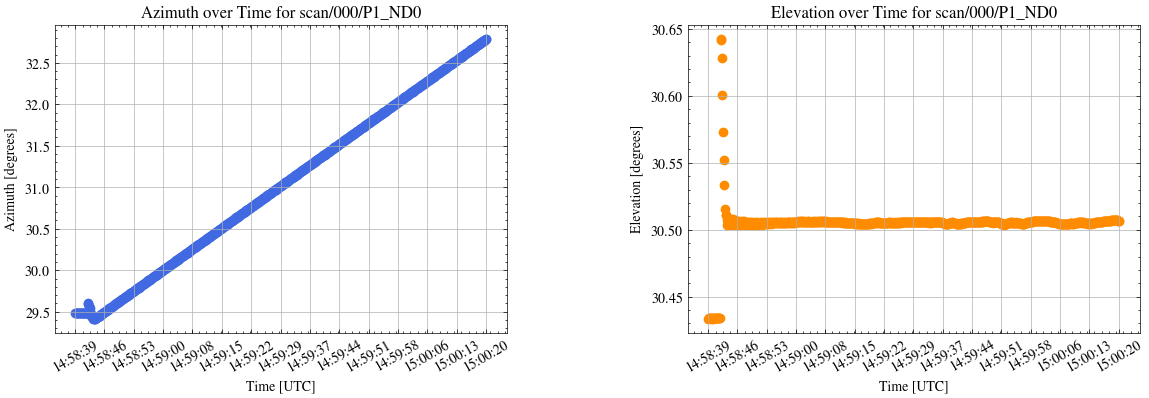

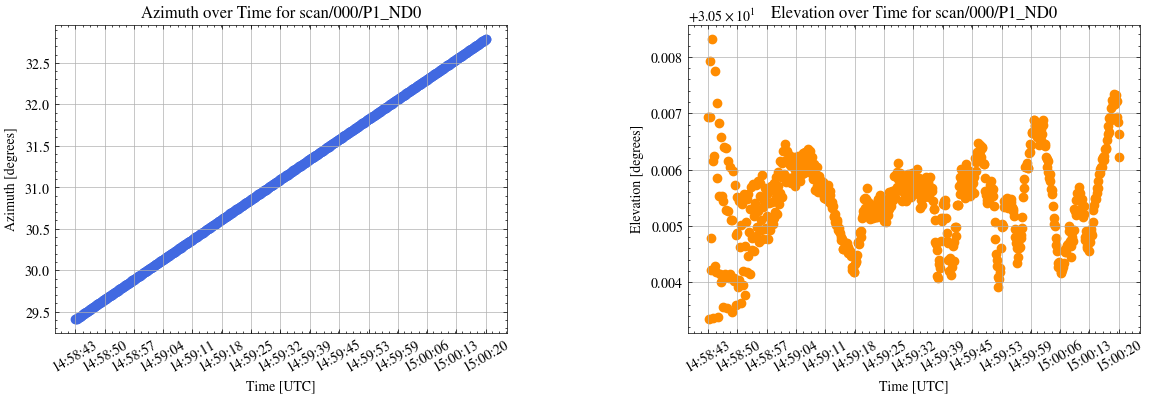

In [7]:
# investigate the variation of azi and elev over time


with h5py.File(fpath, "r") as f:
    try:
        for g in groups:
        
            # --- Access datasets ---
            freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
            spectrum = f[f"{g}/spectrum"][30:,1600:-60]        # (time × freq)
            time = f[f"{g}/timestamp"][:,0]           # time samples
            azi = f[f"{g}/azimuth"][:]              # azimuth angles
            elev = f[f"{g}/elevation"][:]           # elevation angles

            # --- convert time to UTC seconds ---
                    
            # --- Convert time to UTC datetime ---
            time_utc = pd.to_datetime(time, unit='s', utc=True)

            # --- Create figure ---
            fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharex=False)
            plt.subplots_adjust(wspace=0.4)

            # --- Plot azimuth over time ---
            ax[0].scatter(time_utc, azi, color='royalblue')
            ax[0].set_title(f"Azimuth over Time for {g}")
            ax[0].set_xlabel("Time [UTC]")
            ax[0].set_ylabel("Azimuth [degrees]")

            # --- Fixed tick handling ---
            n_ticks = 15
            tick_positions = np.linspace(0, len(time_utc) - 1, n_ticks, dtype=int)
            tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in tick_positions]

            # Use numeric indices for tick positions (since scatter uses time_utc directly)
            ax[0].set_xticks(time_utc[tick_positions])
            ax[0].set_xticklabels(tick_labels, rotation=30)

            ax[0].grid(True)


            # # ️--- Plot elevation over time -
            ax[1].scatter(time_utc, elev, color='darkorange')
            ax[1].set_title(f"Elevation over Time for {g}")
            ax[1].set_xlabel("Time [UTC]")
            ax[1].set_ylabel("Elevation [degrees]")
            ax[1].grid(True)

            # --- Reuse same tick settings for consistency ---
            ax[1].set_xticks(time_utc[tick_positions])
            ax[1].set_xticklabels(tick_labels, rotation=30)


        for g in groups:

             # --- With the Azimuth and Elevation flaged ---



            # --- Access datasets ---
            freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
            spectrum = f[f"{g}/spectrum"][30:,1600:-60]        # (time × freq)
            time = f[f"{g}/timestamp"][30:,0]           # time samples
            azi = f[f"{g}/azimuth"][30:]              # azimuth angles
            elev = f[f"{g}/elevation"][30:]           # elevation angles

            # --- convert time to UTC seconds ---
                    
            # --- Convert time to UTC datetime ---
            time_utc = pd.to_datetime(time, unit='s', utc=True)

            # --- Create figure ---
            fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharex=False)
            plt.subplots_adjust(wspace=0.4)

            plt.title('Azimute and Elevation flaged')

            # --- Plot azimuth over time ---
            ax[0].scatter(time_utc, azi, color='royalblue')
            ax[0].set_title(f"Azimuth over Time for {g}")
            ax[0].set_xlabel("Time [UTC]")
            ax[0].set_ylabel("Azimuth [degrees]")

            # --- Fixed tick handling ---
            n_ticks = 15
            tick_positions = np.linspace(0, len(time_utc) - 1, n_ticks, dtype=int)
            tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in tick_positions]

            # Use numeric indices for tick positions (since scatter uses time_utc directly)
            ax[0].set_xticks(time_utc[tick_positions])
            ax[0].set_xticklabels(tick_labels, rotation=30)

            ax[0].grid(True)

            # # ️--- Plot elevation over time -
            ax[1].scatter(time_utc, elev, color='darkorange')
            ax[1].set_title(f"Elevation over Time for {g}")
            ax[1].set_xlabel("Time [UTC]")
            ax[1].set_ylabel("Elevation [degrees]")
            ax[1].grid(True)

            # --- Reuse same tick settings for consistency ---
            ax[1].set_xticks(time_utc[tick_positions])
            ax[1].set_xticklabels(tick_labels, rotation=30)


    except KeyError as e:
            print(f"  ! Group {g} not found in file.")

In [8]:
time.shape

(634,)

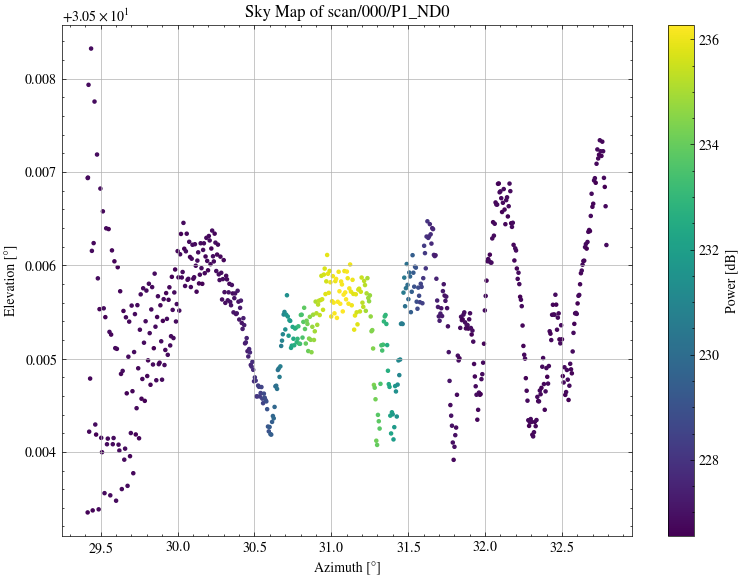

In [9]:
with h5py.File(fpath, "r") as f:
    try:
        for g in groups:
            # --- Access datasets ---
            freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
            spectrum = f[f"{g}/spectrum"][30:,1600:-60]        # (time × freq)
            time = f[f"{g}/timestamp"][30:,0]           # time samples
            azi = f[f"{g}/azimuth"][30:]              # azimuth angles
            elev = f[f"{g}/elevation"][30:]  

            # --- Compute power in dB ---
            spectrum_db = 10 * np.log10(np.mean(spectrum**2, axis=1) + 1e-12)


            # --- Plot Sky Map ---
            plt.figure(figsize=(8, 6))
            sc = plt.scatter(azi, elev, c=spectrum_db, s=5, cmap='viridis')
            plt.xlabel('Azimuth [°]')
            plt.ylabel('Elevation [°]')
            plt.title(f'Sky Map of {g}')
            plt.colorbar(sc, label='Power [dB]')
            plt.grid(True)
            plt.tight_layout()
            plt.show()

    except KeyError as e:
        print(f"  ! Group {g} not found in file.")


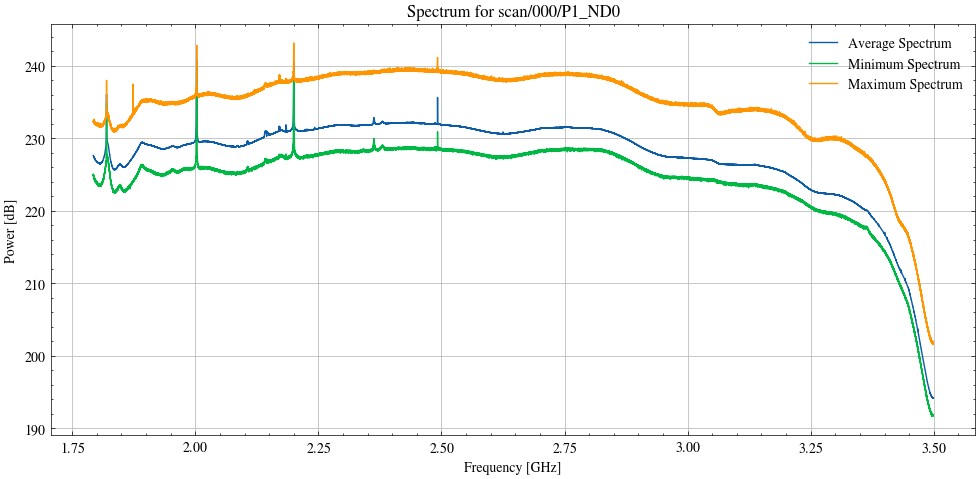

In [10]:



with h5py.File(fpath, "r") as f:
    try:
        for g in groups:
            freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
            spectrum = f[f"{g}/spectrum"][30:,1600:-60]        # (time × freq)
            time = f[f"{g}/timestamp"][30:,0]           # time samples
            azi = f[f"{g}/azimuth"][30:]              # azimuth angles
            elev = f[f"{g}/elevation"][30:]

            # Compute average spectrum
            avg_spectrum = np.mean(spectrum, axis=0)
            # minimum spectrum
            min_spectrum = np.min(spectrum, axis=0)
            # maximum spectra
            max_spectrum = np.max(spectrum, axis=0)

            # Plot both for comparison
            plt.figure(figsize=(10, 5))
            plt.plot(freq, 10 * np.log10(avg_spectrum**2), label="Average Spectrum")
            plt.plot(freq, 10 * np.log10(min_spectrum**2), label="Minimum Spectrum")
            plt.plot(freq, 10 * np.log10(max_spectrum**2), label='Maximum Spectrum')
            
            plt.xlabel("Frequency [GHz]")
            plt.ylabel("Power [dB]")
            plt.title(f"Spectrum for {g}")
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()
            
    except KeyError as e:
        print(f"! Group {g} not found in file: {e}")

# Signal pre-processing

* 1. Signal detrendig using `pybaseline` with the method AsLs;
* 2. Covert the linear scale to log scale;




In [11]:

# Baseline correction

def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline



In [12]:
# Define a function to quantify the RFI width
def quantify_RFI_width(freq, power, ax=None):
    """
    Quantify how wide an RFI peak is in frequency.

    Parameters:
    freq : array
        Frequency array.
    power : array
        Power array with baseline corrected.
    mask : boolean array
        Mask to select the frequency window of interest.

    Returns:
    start_freq : float
        Frequency where power rises above threshold.
    end_freq : float
        Frequency where power falls below threshold.
    peak_freq : float
        Frequency of the peak power.
    peak_power : float
        Value of the peak power.
    """


    # --- 1) Find where power rises above zero ---
    threshold = 0.05  # small threshold 
    above_threshold = np.where(power > threshold)[0]

    if len(above_threshold) > 0:
        start_index = above_threshold[0]
        end_index = above_threshold[-1]
        start_freq = freq[start_index]
        end_freq = freq[end_index]
    else:
        start_freq = end_freq = np.nan
        print("No significant power detected in the masked range.")

    # --- 2) Find the frequency of the peak ---
    peak_index = np.argmax(power)
    peak_freq = freq[peak_index]
    peak_power = power[peak_index]


    print(f"Start Frequency: {start_freq:.4f} GHz")
    print(f"End Frequency: {end_freq:.4f} GHz")
    print(f"Peak Frequency: {peak_freq:.4f} GHz with Power: {peak_power:.4f} dB")


    # Number of channels corrupted.
    delta_frequency = (freq[1] - freq[0])  # spectral resolution / channel width
    chans = ((end_freq - start_freq) / delta_frequency)


    print(f'Number off corrupted channels: {chans: .1f}')


    # --- Plot results ---

    if ax is None:
        fig,ax = plt.subplots(figsize=(12,6))

    ax.plot(freq, power, '.', color='steelblue', label='Data')
    ax.axvline(start_freq, color='green', linestyle='--', label='Start')
    ax.axvline(peak_freq, color='red', linestyle='-', label='Peak')
    ax.axvline(end_freq, color='orange', linestyle='--', label='End')
    ax.set_xlabel('Frequency [GHz]', fontsize=16)
    ax.set_ylabel('Power [dB]', fontsize=16)
    ax.legend(fontsize=14)
    ax.grid(linestyle='--')

    return start_freq, end_freq, peak_freq, peak_power



# Waterfall plot function for specified frequency range
def waterfall_timevsfreq(time, freq, spectrum, freq_mask, ax=None):
    """
    Generate a waterfall plot of power vs time and frequency.

    Parameters:
    time : array
        Time array in seconds since epoch.
    freq : array
        Frequency array in GHz.
    spectrum : 2D array
        Power spectrum with shape (time, frequency).
    freq_mask : boolean array
        Mask to select the frequency range of interest.
   ax : matplotlib.axes.Axes, optional
        Axis on which to draw the plot. If None, creates a new one.

    Returns:
    ax : matplotlib.axes.Axes
        The axis with the plotted data.
    """

    # --- Convert Power Spectrum to dB ---
    spectrum_db = 10 * np.log10(spectrum**2 + 1e-12)

    # Select the desired frequency channels
    power_channel = spectrum_db[:, freq_mask]

    # --- Convert Time to UTC Datetime ---
    time_utc = pd.to_datetime(time, unit="s", utc=True)

    # --- Select Frequency Range (GHz) ---
    freq_sel = freq[freq_mask]

    # --- Plot Waterfall (Frequency on x, Time on y) ---

    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))

    # --- Create Waterfall ---
    im = ax.imshow(
        power_channel,
        aspect='auto',
        origin='lower',
        extent=[freq_sel.min(), freq_sel.max(), 0, len(time_utc)],
        cmap='viridis'
    )

    # --- Colorbar ---

    cbar = plt.colorbar(im, ax=ax, label='Power [dB]')
    cbar.ax.tick_params(labelsize=14)       # set tick label size
    cbar.set_label('Power [dB]', fontsize=16)  # set label font size
    
    ax.set_xlabel('Frequency [GHz]', fontsize=16)
    ax.set_ylabel('Time [UTC]', fontsize=16)
    #plt.title('Waterfall Plot: Time vs Frequency', fontsize=18)

    # --- Y-axis: Time Ticks (UTC) ---
    n_ticks = 10
    tick_positions = np.linspace(0, len(time_utc) - 1, n_ticks, dtype=int)
    tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in tick_positions]
    ax.set_yticks(tick_positions)
    ax.set_yticklabels(tick_labels)

    # --- X-axis: Frequency ---
    ax.set_xlim(freq_sel.min(), freq_sel.max())
    ax.grid(False)





In [13]:
# automate power epectrum inspection

# Gaussian Fitting

def gaussian_fit_RFI (frequency, power, tie, ax=None):
    """ 
    The function, fittis a gaussian function to a frequency window

    Entries
    --------
    frequency: array
    power: array
    freq_min, freq_mac: frequency window
    tie: bolean - fit one or to gaussian 
        
    """

    # --- Initial Guess ---
    peak_idx = np.argmax(power)
    peak_amplitude = power[peak_idx]
    peak_frequency = frequency[peak_idx]

    # Estimate standard deviation for narrow gaussian
    delta_frequency = (frequency[1] - frequency[0])  # chanel width
    sigma_narrow = 5 * delta_frequency


    # Estimate sigma for broad band 
    median_amplitude = np.median(power)
    sigma_broad = 0.01
    amp_broad = (peak_amplitude - median_amplitude) / 5 


    # create a gaussian model for each 
    g_narrow = models.Gaussian1D(amplitude=peak_amplitude, mean=peak_frequency, stddev=sigma_narrow)
    g_broad  = models.Gaussian1D(amplitude=amp_broad, mean=peak_frequency, stddev=sigma_broad)


    if tie==True:
        # Tie the broad with the narrow
        def tie_means(model):
            return model.mean_0
        g_broad.mean.tied = tie_means

        # combine them
        model_init = g_narrow + g_broad

        # Fitt the model
        fitter = fitting.LMLSQFitter()
        fitted_model = fitter(model_init, frequency, power)

        # Calculate the Root Mean Squared Error (RMSE)
        residuals = power - fitted_model(frequency)
        res_mean = np.mean(residuals)
        rmse = np.sqrt(np.mean(residuals**2))
        print(f'The Root Mean Squared Error: {rmse:.3f}')

        # Calculate the Chi-square
        chi2 = np.sum(residuals / np.std(power)**2)
        reduce_chi_square = chi2 / (len(frequency) - len(fitted_model.param_names))
        print(f'The reduce_chi-square is: {reduce_chi_square:.3f}')

        # Calculate the fwhm
        sigma = fitted_model.stddev_0.value + fitted_model.stddev_0.value
        fwhm = 2.355 * sigma
        chans = np.ceil(fwhm / delta_frequency)
        print(f'Number off corrupted channels: {chans}')
        my_label = '2 Gaussian Fit'
    
    else:
        # -- Fit the Gaussian ---
        fitter = fitting.LMLSQFitter()
        fitted_model = fitter(g_narrow,frequency,power)


        # Calculate the Root Mean Squared Error (RMSE)
        residuals = power - fitted_model(frequency)
        res_mean = np.mean(residuals)
        rmse = np.sqrt(np.mean(residuals**2))
        print(f'The Root Mean Squared Error: {rmse:.3f}')

        # Calculate the Chi-square
        chi2 = np.sum(residuals / np.std(power)**2)
        reduce_chi_square = chi2 / (len(power) - len(fitted_model.param_names))
        print(f'The Chi-square is: {reduce_chi_square:.3f}')

        # Extrat fit parameters
        sigma = fitted_model.stddev.value
        fwhm = 2.355 * sigma
        chans = np.ceil(fwhm / delta_frequency)
        print(f'Number off corrupted channels: {chans}')
        my_label = 'Gaussian Fit'


    if ax is None:
        fig, ax = plt.subplots(figsize=(12,6))
    ax.plot(frequency, power, '.', label="Data")
    ax.plot(frequency, fitted_model(frequency), 'r-', label=my_label)
    ax.set_xlabel("Frequency [GHz]")
    ax.set_ylabel("Power [db]")
    ax.legend()
    ax.grid(True, alpha=0.3)





=== Date: 2023-03-11T14 | Group: scan/000/P1_ND0 ===
Start Frequency: 2.0000 GHz
End Frequency: 2.0070 GHz
Peak Frequency: 2.0028 GHz with Power: 240.7392 dB
Number off corrupted channels:  261.0
The Root Mean Squared Error: 2.194
The Chi-square is: 0.000
Number off corrupted channels: 1523.0


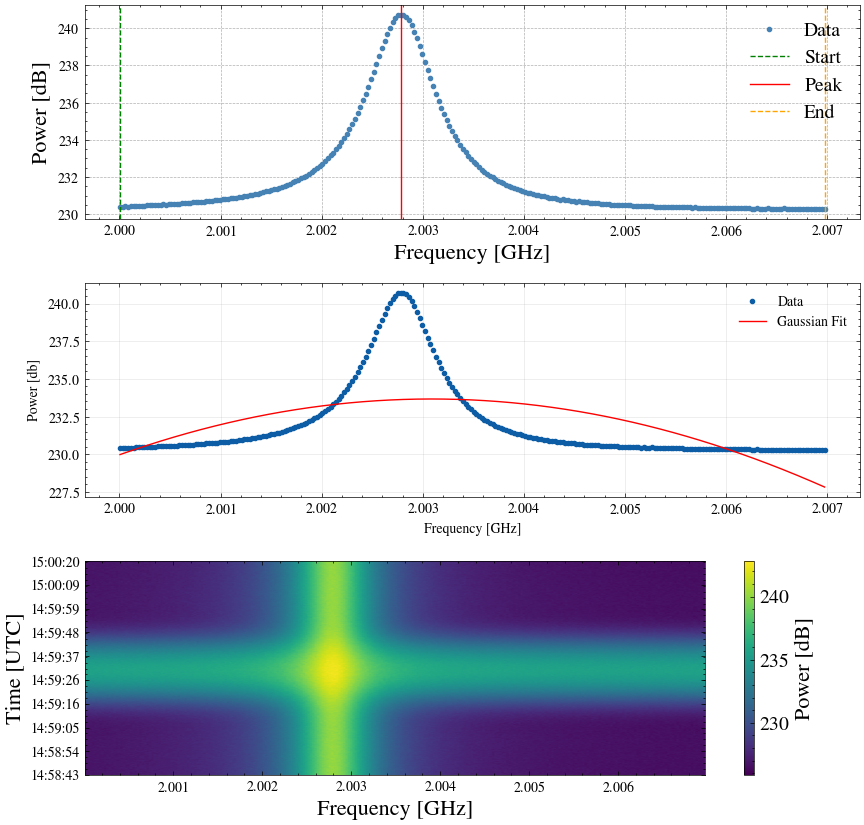

In [14]:

with h5py.File(fpath, "r") as f:
    base = os.path.basename(fpath)
    name = base.replace(".hdf5", "")
    date_code = name.split("_")[1]
    try:
        for g in groups:

            freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
            spectrum = f[f"{g}/spectrum"][30:,1600:-60]        # (time × freq)
            time = f[f"{g}/timestamp"][30:,0]           # time samples
            azi = f[f"{g}/azimuth"][30:]              # azimuth angles
            elev = f[f"{g}/elevation"][30:]

            spectrum_dB = 10 *np.log10(np.mean(spectrum**2, axis=0))


            # -- Define frequency mask around 2.00 GHz ---
            mask = (freq > 2.00) & (freq < 2.007)


                # --- plot the spectrum around 2.00 GHz --

            print(f"\n=== Date: {date_code} | Group: {g} ===")
            fig, ax = plt.subplots(3,1, figsize=(10, 10))
            plt.subplots_adjust(hspace=0.3,)

            quantify_RFI_width(freq[mask], spectrum_dB[mask], ax=ax[0])
            gaussian_fit_RFI(freq[mask], spectrum_dB[mask], tie=False,ax=ax[1] )
            waterfall_timevsfreq(time, freq, spectrum, mask, ax=ax[2])

            plt.show()
                    
    except KeyError as e:
        print(f"! Group {g} not found in file: {e}")

Detected peak > 1σ are frequencies (GHz): ['1.8196', '2.0028', '2.1999', '2.3628', '2.4920', '2.6250']
Detected peak > 3σ are frequencies (GHz): ['1.8196', '2.0028', '2.1999', '2.4920']


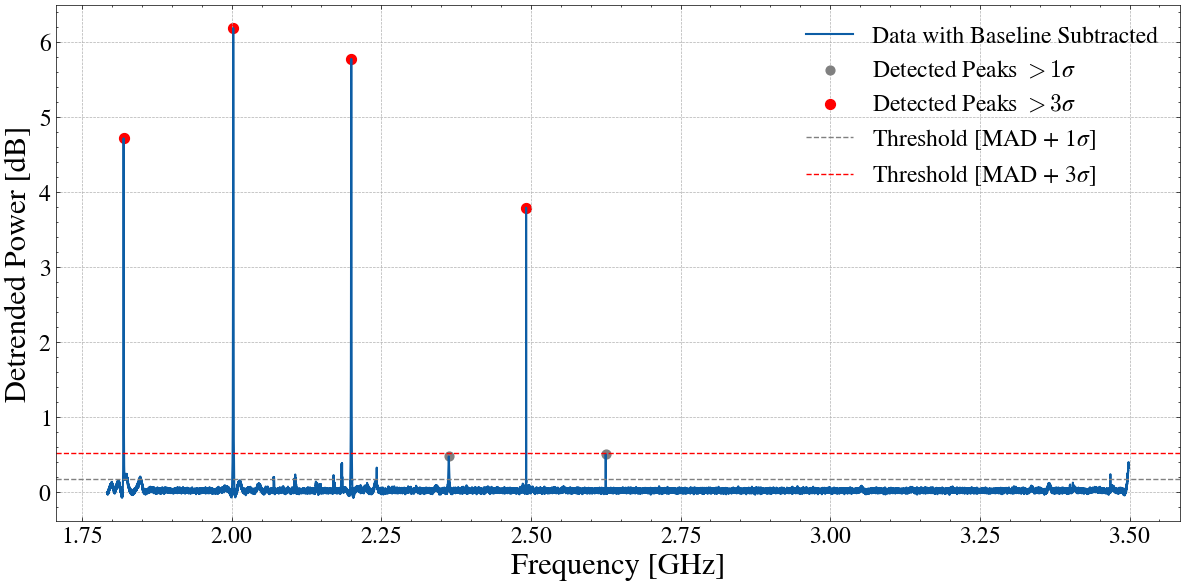

In [22]:
# Base line corrected and peaks detection
for g in groups:

    power_base_core = base_correction(freq, spectrum_dB)

        
    # Find peaks above 1 sigma from the MAD
    peaks, propreties = find_peaks(power_base_core, 
                                height=MAD(power_base_core) + np.std(power_base_core),
                                distance=10,
                                prominence=0.5
                                )
    # Find peaks above 3 sigma from the MAD
    peaks1, propreties1 = find_peaks(power_base_core, 
                                height=MAD(power_base_core) + 3*np.std(power_base_core),
                                distance=10,
                                prominence=0.5
                                )

    plt.figure(figsize=(12, 6))

    # --- Plot baseline-corrected spectrum ---
    plt.plot(freq, power_base_core, label=f'Data with Baseline Subtracted', lw=1.5)

    # --- Plot detected peaks ---
    plt.scatter(freq[peaks], power_base_core[peaks], 
                color='gray', s=40, label='Detected Peaks $> 1σ$')

    plt.scatter(freq[peaks1], power_base_core[peaks1], 
                color='red', s=50, label='Detected Peaks $> 3σ$')

    # --- Plot threshold lines ---
    plt.axhline(y=MAD(power_base_core) + np.std(power_base_core), 
                color='gray', linestyle='--', label='Threshold [MAD + 1$σ$]')

    plt.axhline(y=MAD(power_base_core) + 3*np.std(power_base_core), 
            color='red', linestyle='--', label='Threshold [MAD + 3$σ$]')

    # --- Labels and formatting ---
    plt.xlabel("Frequency [GHz]",fontsize=22)
    plt.ylabel("Detrended Power [dB]",fontsize=22)
    #plt.title("Detected Peaks in Baseline Corrected Spectrum", fontsize=18)
    plt.grid(True, linestyle='--')
    plt.tight_layout()
    plt.legend(fontsize=17)
    plt.xticks(fontsize=17)
    plt.yticks(fontsize=17)

   #plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.png', dpi=300)
   #plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.pdf', dpi=300)


    # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in freq[peaks]]
    formatted_freqs1 = [f"{f:.4f}" for f in freq[peaks1]]

    print(f"Detected peak > 1σ are frequencies (GHz): {formatted_freqs}")
    print(f"Detected peak > 3σ are frequencies (GHz): {formatted_freqs1}")



In [16]:
# automate power epectrum inspection

# Gaussian Fitting

def gaussian_fit_RFI1 (frequency, power, tie):
    """ 
    The function, fittis a gaussian function to a frequency window

    Entries
    --------
    frequency: array
    power: array
    freq_min, freq_mac: frequency window
    tie: bolean - fit one or to gaussian 
        
    """

    # --- Initial Guess ---
    peak_idx = np.argmax(power)
    peak_amplitude = power[peak_idx]
    peak_frequency = frequency[peak_idx]

    # Estimate standard deviation for narrow gaussian
    delta_frequency = (frequency[1] - frequency[0])  # chanel width
    sigma_narrow = 5 * delta_frequency


    # Estimate sigma for broad band 
    median_amplitude = np.median(power)
    sigma_broad = 0.01
    amp_broad = (peak_amplitude - median_amplitude) / 5 


    # create a gaussian model for each 
    g_narrow = models.Gaussian1D(amplitude=peak_amplitude, mean=peak_frequency, stddev=sigma_narrow)
    g_broad  = models.Gaussian1D(amplitude=amp_broad, mean=peak_frequency, stddev=sigma_broad)


    if tie==True:
        # Tie the broad with the narrow
        def tie_means(model):
            return model.mean_0
        g_broad.mean.tied = tie_means

        # combine them
        model_init = g_narrow + g_broad

        # Fitt the model
        fitter = fitting.LMLSQFitter()
        fitted_model = fitter(model_init, frequency, power)

        # Calculate the Root Mean Squared Error (RMSE)
        residuals = power - fitted_model(frequency)
        res_mean = np.mean(residuals)
        rmse = np.sqrt(np.mean(residuals**2))
        print(f'The Root Mean Squared Error: {rmse:.3f}')

        # Calculate the Chi-square
        chi2 = np.sum(residuals / np.std(power)**2)
        reduce_chi_square = chi2 / (len(frequency) - len(fitted_model.param_names))
        print(f'The reduce_chi-square is: {reduce_chi_square:.3f}')

        # Calculate the fwhm
        sigma = fitted_model.stddev_0.value + fitted_model.stddev_0.value
        fwhm = 2.355 * sigma
        chans = np.ceil(fwhm / delta_frequency)
        print(f'Number off corrupted channels: {chans}')
        my_label = '2 Gaussian Fit'
    
    else:
        # -- Fit the Gaussian ---
        fitter = fitting.LMLSQFitter()
        fitted_model = fitter(g_narrow,frequency,power)


        # Calculate the Root Mean Squared Error (RMSE)
        residuals = power - fitted_model(frequency)
        res_mean = np.mean(residuals)
        rmse = np.sqrt(np.mean(residuals**2))
        print(f'The Root Mean Squared Error: {rmse:.3f}')

        # Calculate the Chi-square
        chi2 = np.sum(residuals / np.std(power)**2)
        reduce_chi_square = chi2 / (len(power) - len(fitted_model.param_names))
        print(f'The Chi-square is: {reduce_chi_square:.3f}')

        # Extrat fit parameters
        sigma = fitted_model.stddev.value
        fwhm = 2.355 * sigma
        chans = np.ceil(fwhm / delta_frequency)
        print(f'Number off corrupted channels: {chans}')
        my_label = 'Gaussian Fit'


    # entreduce a subplot of residual and put the horizontal line for the mean and RMSE
    
    plt.figure(figsize=(12, 6))
    plt.plot(frequency, power, '.', label="Data")
    plt.plot(frequency, fitted_model(frequency), 'r-', label=my_label)
    plt.xlabel("Frequency [GHz]")
    plt.ylabel("Power [db]")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()




The Root Mean Squared Error: 2.194
The Chi-square is: 0.000
Number off corrupted channels: 1523.0


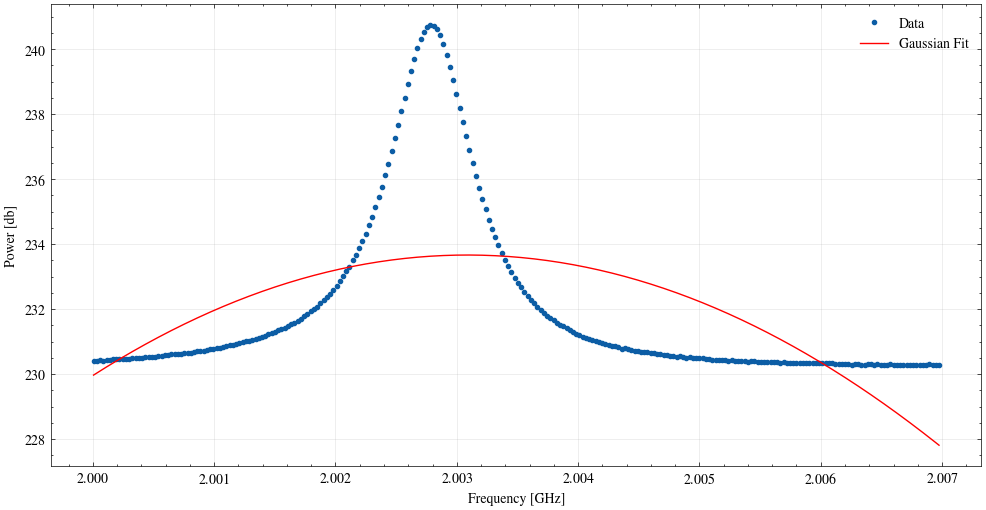

In [17]:
mask1 = (freq > 1.807) & (freq < 1.835) 

fitted = gaussian_fit_RFI1(freq[mask], spectrum_dB[mask], tie=False)


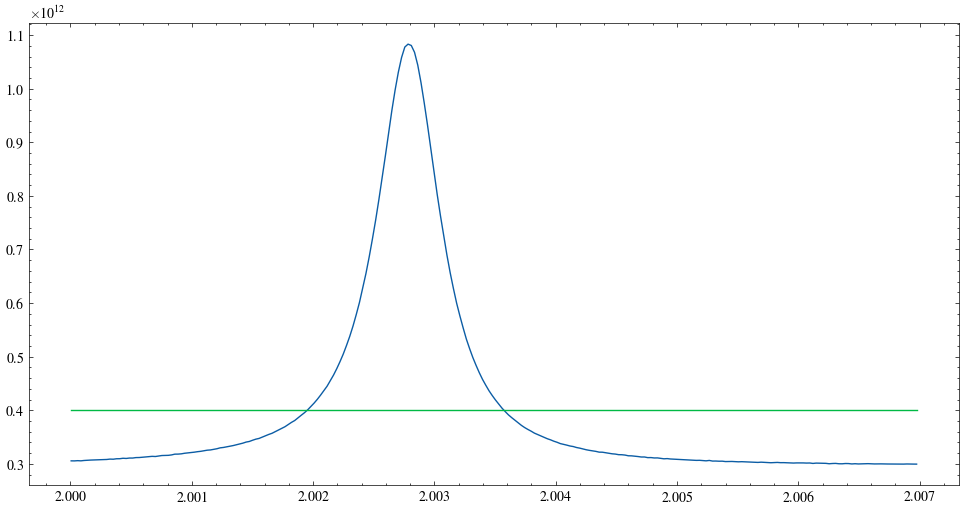

In [18]:
peak_idx = np.argmax(avg_spectrum)
peak_amplitude = avg_spectrum[peak_idx]
peak_frequency = freq[peak_idx]

g_int = models.Gaussian1D(amplitude=peak_amplitude, mean=np.median(avg_spectrum), stddev=np.std(avg_spectrum))
fit = fitting.LevMarLSQFitter()

g=fit(g_int,freq[mask],avg_spectrum[mask])

plt.figure(figsize=(12,6))
plt.plot(freq[mask], avg_spectrum[mask])
plt.plot(freq[mask], g(freq[mask]))



=== Date: 2023-03-11T14 | Group: scan/000/P1_ND0 ===
Start Frequency: 2.0003 GHz
End Frequency: 2.0048 GHz
Peak Frequency: 2.0028 GHz with Power: 10.2505 dB
Number off corrupted channels:  169.0


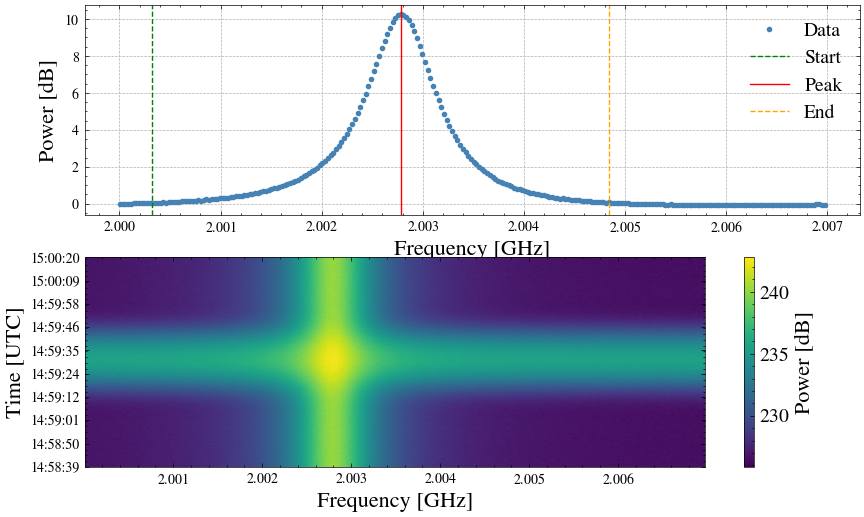

In [19]:
# plot the spectrum the around the frequency 2.00 GHz

for fpath in hdf5_files:
    base = os.path.basename(fpath)
    name = base.replace(".hdf5", "")
    date_code = name.split("_")[1]

    with h5py.File(fpath, "r") as f:
        try:
            
            for g in groups:
                    # --- Access datasets ---
                freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
                spectrum = f[f"{g}/spectrum"][:,1600:-60]        # (time × freq)
                time = f[f"{g}/timestamp"][:,0]           # time samples

                # --- Convert the variables ---
                spectrum_dB = 10 * np.log10(np.mean(spectrum**2, axis=0) + 1e-12)  # mean over time, convert to dB

                # --- Baseline correction ---
                spectrum_corrected = base_correction(freq, spectrum_dB)

                # -- Define frequency mask around 2.00 GHz ---
                mask = (freq > 2.00) & (freq < 2.007)


                 # --- plot the spectrum around 2.00 GHz --
    
                print(f"\n=== Date: {date_code} | Group: {g} ===")
                fig, ax = plt.subplots(2,1, figsize=(10, 6))
                

                quantify_RFI_width(freq[mask], spectrum_corrected[mask], ax=ax[0])
                waterfall_timevsfreq(time, freq, spectrum, mask, ax=ax[1])

                plt.show()


        except KeyError:
            print(f"  [!] Missing data for {g} for {date_code}")


    
    break
        

            


=== Date: 2023-03-11T14 | Group: scan/000/P1_ND0 ===
Start Frequency: 2.0003 GHz
End Frequency: 2.0048 GHz
Peak Frequency: 2.0028 GHz with Power: 10.1646 dB
Number off corrupted channels:  169.0


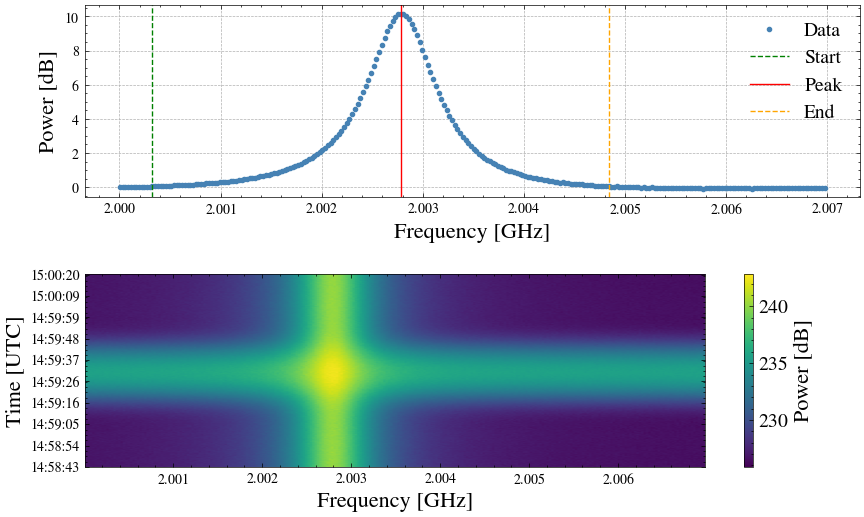


=== Date: 2023-03-11T14 | Group: scan/000/P1_ND1 ===
Start Frequency: 2.0004 GHz
End Frequency: 2.0049 GHz
Peak Frequency: 2.0028 GHz with Power: 9.5739 dB
Number off corrupted channels:  170.0


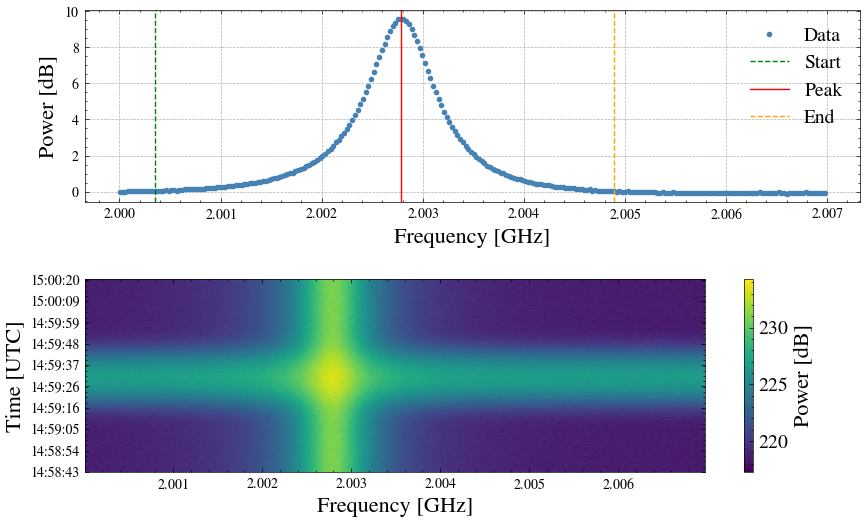


=== Date: 2023-03-11T14 | Group: scan/001/P0_ND0 ===
Start Frequency: 2.0008 GHz
End Frequency: 2.0047 GHz
Peak Frequency: 2.0028 GHz with Power: 6.5766 dB
Number off corrupted channels:  146.0


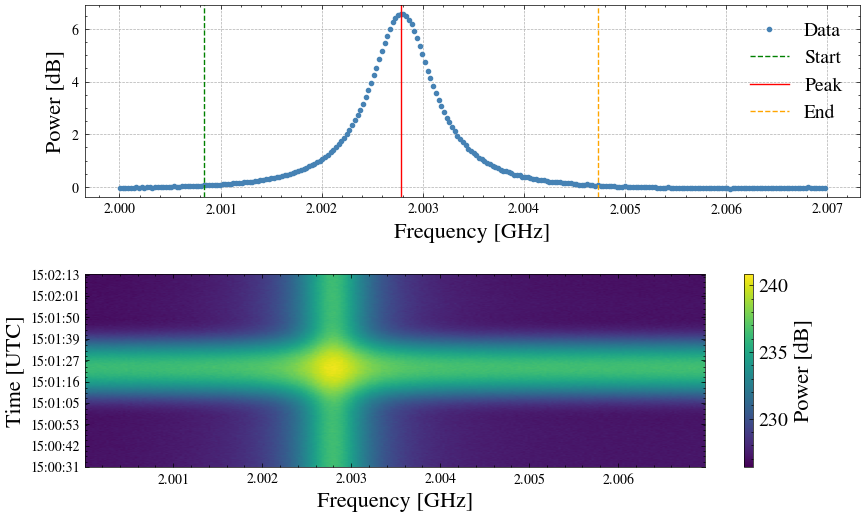


=== Date: 2023-03-11T14 | Group: scan/001/P0_ND1 ===
Start Frequency: 2.0008 GHz
End Frequency: 2.0048 GHz
Peak Frequency: 2.0028 GHz with Power: 6.1853 dB
Number off corrupted channels:  151.0


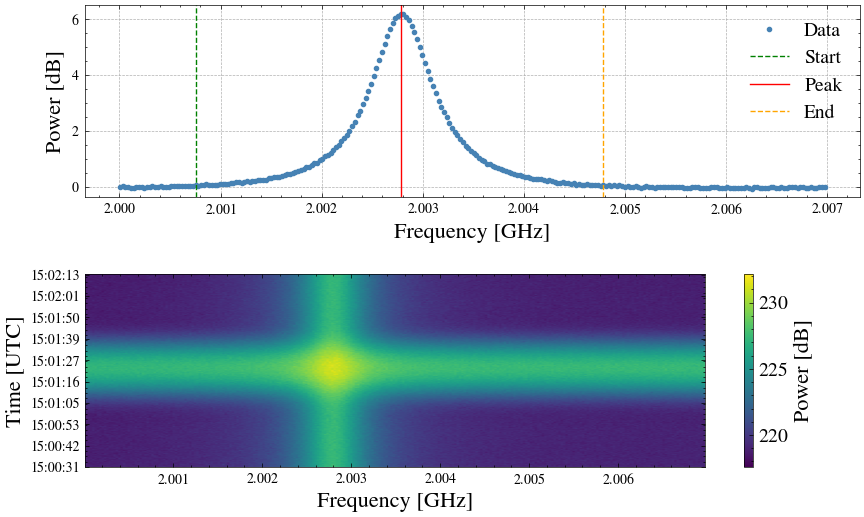

In [20]:
group1 = [
    "scan/000/P1_ND0",
     "scan/000/P1_ND1",
]

group2 = [
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
]


# plot the spectrum the around the frequency 2.00 GHz

for fpath in hdf5_files:
    base = os.path.basename(fpath)
    name = base.replace(".hdf5", "")
    date_code = name.split("_")[1]

    with h5py.File(fpath, "r") as f:
        try:
            
            for g in group1:
                    # --- Access datasets ---
                freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
                spectrum = f[f"{g}/spectrum"][30:,1600:-60]        # (time × freq)
                time = f[f"{g}/timestamp"][30:,0]           # time samples

                # --- Convert the variables ---
                spectrum_dB = 10 * np.log10(np.mean(spectrum**2, axis=0) + 1e-12)  # mean over time, convert to dB

                # --- Baseline correction ---
                spectrum_corrected = base_correction(freq, spectrum_dB)

                # -- Define frequency mask around 2.00 GHz ---
                mask = (freq > 2.00) & (freq < 2.007)


                 # --- plot the spectrum around 2.00 GHz --
    
                print(f"\n=== Date: {date_code} | Group: {g} ===")
                fig, ax = plt.subplots(2,1, figsize=(10, 6))
                plt.subplots_adjust(hspace=0.4)
                

                quantify_RFI_width(freq[mask], spectrum_corrected[mask], ax=ax[0])
                waterfall_timevsfreq(time, freq, spectrum, mask, ax=ax[1])

                plt.show()


            for g in group2:
                    # --- Access datasets ---
                freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
                spectrum = f[f"{g}/spectrum"][:,1600:-60]        # (time × freq)
                time = f[f"{g}/timestamp"][:,0]           # time samples

                # --- Convert the variables ---
                spectrum_dB = 10 * np.log10(np.mean(spectrum**2, axis=0) + 1e-12)  # mean over time, convert to dB

                # --- Baseline correction ---
                spectrum_corrected = base_correction(freq, spectrum_dB)

                # -- Define frequency mask around 2.00 GHz ---
                mask = (freq > 2.00) & (freq < 2.007)


                 # --- plot the spectrum around 2.00 GHz --
    
                print(f"\n=== Date: {date_code} | Group: {g} ===")
                fig, ax = plt.subplots(2,1, figsize=(10, 6))
                plt.subplots_adjust(hspace=0.4)                

                quantify_RFI_width(freq[mask], spectrum_corrected[mask], ax=ax[0])
                waterfall_timevsfreq(time, freq, spectrum, mask, ax=ax[1])

                plt.show()


        except KeyError:
            print(f"  [!] Missing data for {g} for {date_code}")


    
    break
        

            